# Vehicle Detection with Roboflow + YOLOv12

1. Install dependencies
2. Download the dataset from Roboflow
3. Train a YOLOv12 model
4. Evaluate on the validation / test set
5. Run inference on new images
6. Run on a video with tracking

## 1. Install dependencies

In [1]:
# CUDA-enabled PyTorch first (on Windows, plain pip installs the CPU-only build)
%pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu124
%pip install -q roboflow "ultralytics>=8.3.78" lap  # lap is needed for tracking
# Restart the kernel after this cell finishes

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mediapipe 0.10.21 requires numpy<2, but you have numpy 2.3.5 which is incompatible.
pandas 2.1.3 requires numpy<2,>=1.26.0; python_version >= "3.12", but you have numpy 2.3.5 which is incompatible.
scikit-learn 1.3.2 requires numpy<2.0,>=1.17.3, but you have numpy 2.3.5 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.3.5 which is incompatible.
tensorflow-intel 2.18.0 requires ml-dtypes<0.5.0,>=0.4.0, but you have ml-dtypes 0.5.1 which is incompatible.
tensorflow-intel 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.3.5 which is incompatible.
tensorflow-intel 2.18.0 requires tensorboard<2.19,>=2.18, but you have tensorboard 2.19.0 which is incompatible.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip insta

In [3]:
import torch
import ultralytics

ultralytics.checks()
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Using device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

Ultralytics 8.4.165  Python-3.12.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Setup complete  (16 CPUs, 15.7 GB RAM, 403.6/452.5 GB disk)
Using device: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Get the dataset from Roboflow

Downloads only if `car-detection-1/` isn't already on disk. The API key is read from the `ROBOFLOW_API_KEY` environment variable (or prompted for) so it doesn't get saved inside the notebook.

In [5]:
import os
from pathlib import Path

DATASET_DIR = Path("car-detection-1")

if not (DATASET_DIR / "data.yaml").exists():
    from getpass import getpass
    from roboflow import Roboflow

    api_key = os.environ.get("ROBOFLOW_API_KEY") or getpass("Roboflow API key: ")
    rf = Roboflow(api_key=api_key)
    project = rf.workspace("dhafer").project("car-detection-9mxpz-pvcxe")
    version = project.version(1)
    version.download("yolov12", location=str(DATASET_DIR))

DATA_YAML = str(DATASET_DIR.resolve() / "data.yaml")
# Absolute path so all outputs land in this project folder, not Ultralytics' global runs_dir
RUNS_DIR = Path("runs").resolve()
print("Using dataset at:", DATASET_DIR.resolve())

Using dataset at: C:\Users\dhafe\Desktop\Vehicle-detection\car-detection-1


In [6]:
# Inspect classes and split sizes
import yaml
from pathlib import Path

with open(DATA_YAML) as f:
    data_cfg = yaml.safe_load(f)
print("Classes:", data_cfg["names"])

for split in ["train", "valid", "test"]:
    img_dir = DATASET_DIR / split / "images"
    if img_dir.exists():
        print(f"{split:5s}: {len(list(img_dir.glob('*')))} images")

Classes: ['big bus', 'big truck', 'bus-l-', 'bus-s-', 'car', 'mid truck', 'small bus', 'small truck', 'truck-l-', 'truck-m-', 'truck-s-', 'truck-xl-']
train: 2634 images
valid: 966 images
test : 458 images


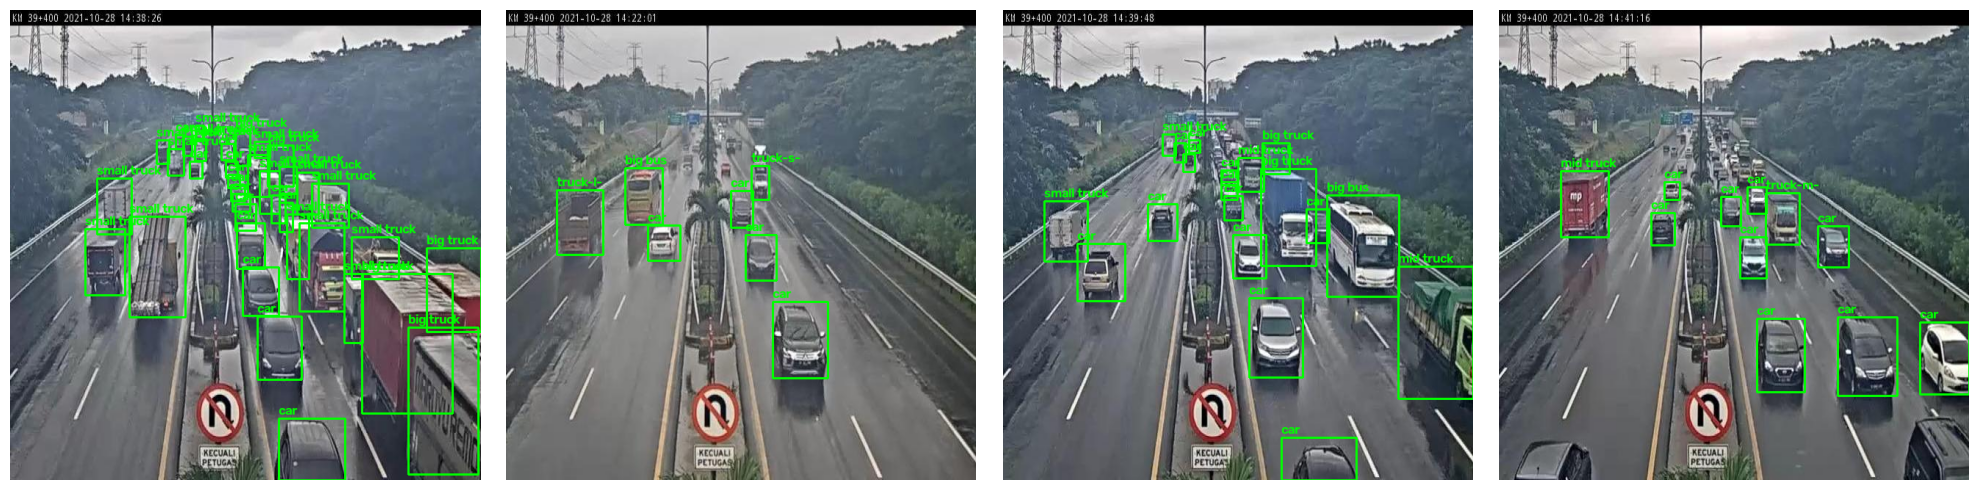

In [7]:
# Visualise a few labelled training images
import random
import cv2
import matplotlib.pyplot as plt

train_imgs = list((DATASET_DIR / "train" / "images").glob("*"))
samples = random.sample(train_imgs, min(4, len(train_imgs)))

fig, axes = plt.subplots(1, len(samples), figsize=(5 * len(samples), 5))
for ax, img_path in zip(axes if len(samples) > 1 else [axes], samples):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    label_path = img_path.parent.parent / "labels" / (img_path.stem + ".txt")
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue  # skip polygon labels
            cls, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:])
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(img, str(data_cfg["names"][cls]), (x1, max(y1 - 5, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    ax.imshow(img)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Train YOLOv12

`yolo12n.pt` is the smallest (nano) variant, which fits comfortably on a 4 GB laptop GPU. Swap in `yolo12s.pt` for higher accuracy if you have the memory. Lower `batch` if you hit a CUDA out-of-memory error.

In [6]:
from ultralytics import YOLO

model = YOLO("yolo12n.pt")  # COCO-pretrained weights, fine-tuned on our dataset

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=8,
    device=DEVICE,
    workers=0,        # avoids multiprocessing issues in Jupyter on Windows
    patience=15,      # early stopping
    project=str(RUNS_DIR),
    name="vehicle_yolo12n",
    exist_ok=True,
)

Ultralytics 8.4.165  Python-3.12.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\dhafe\Desktop\Vehicle-detection\car-detection-1\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ve

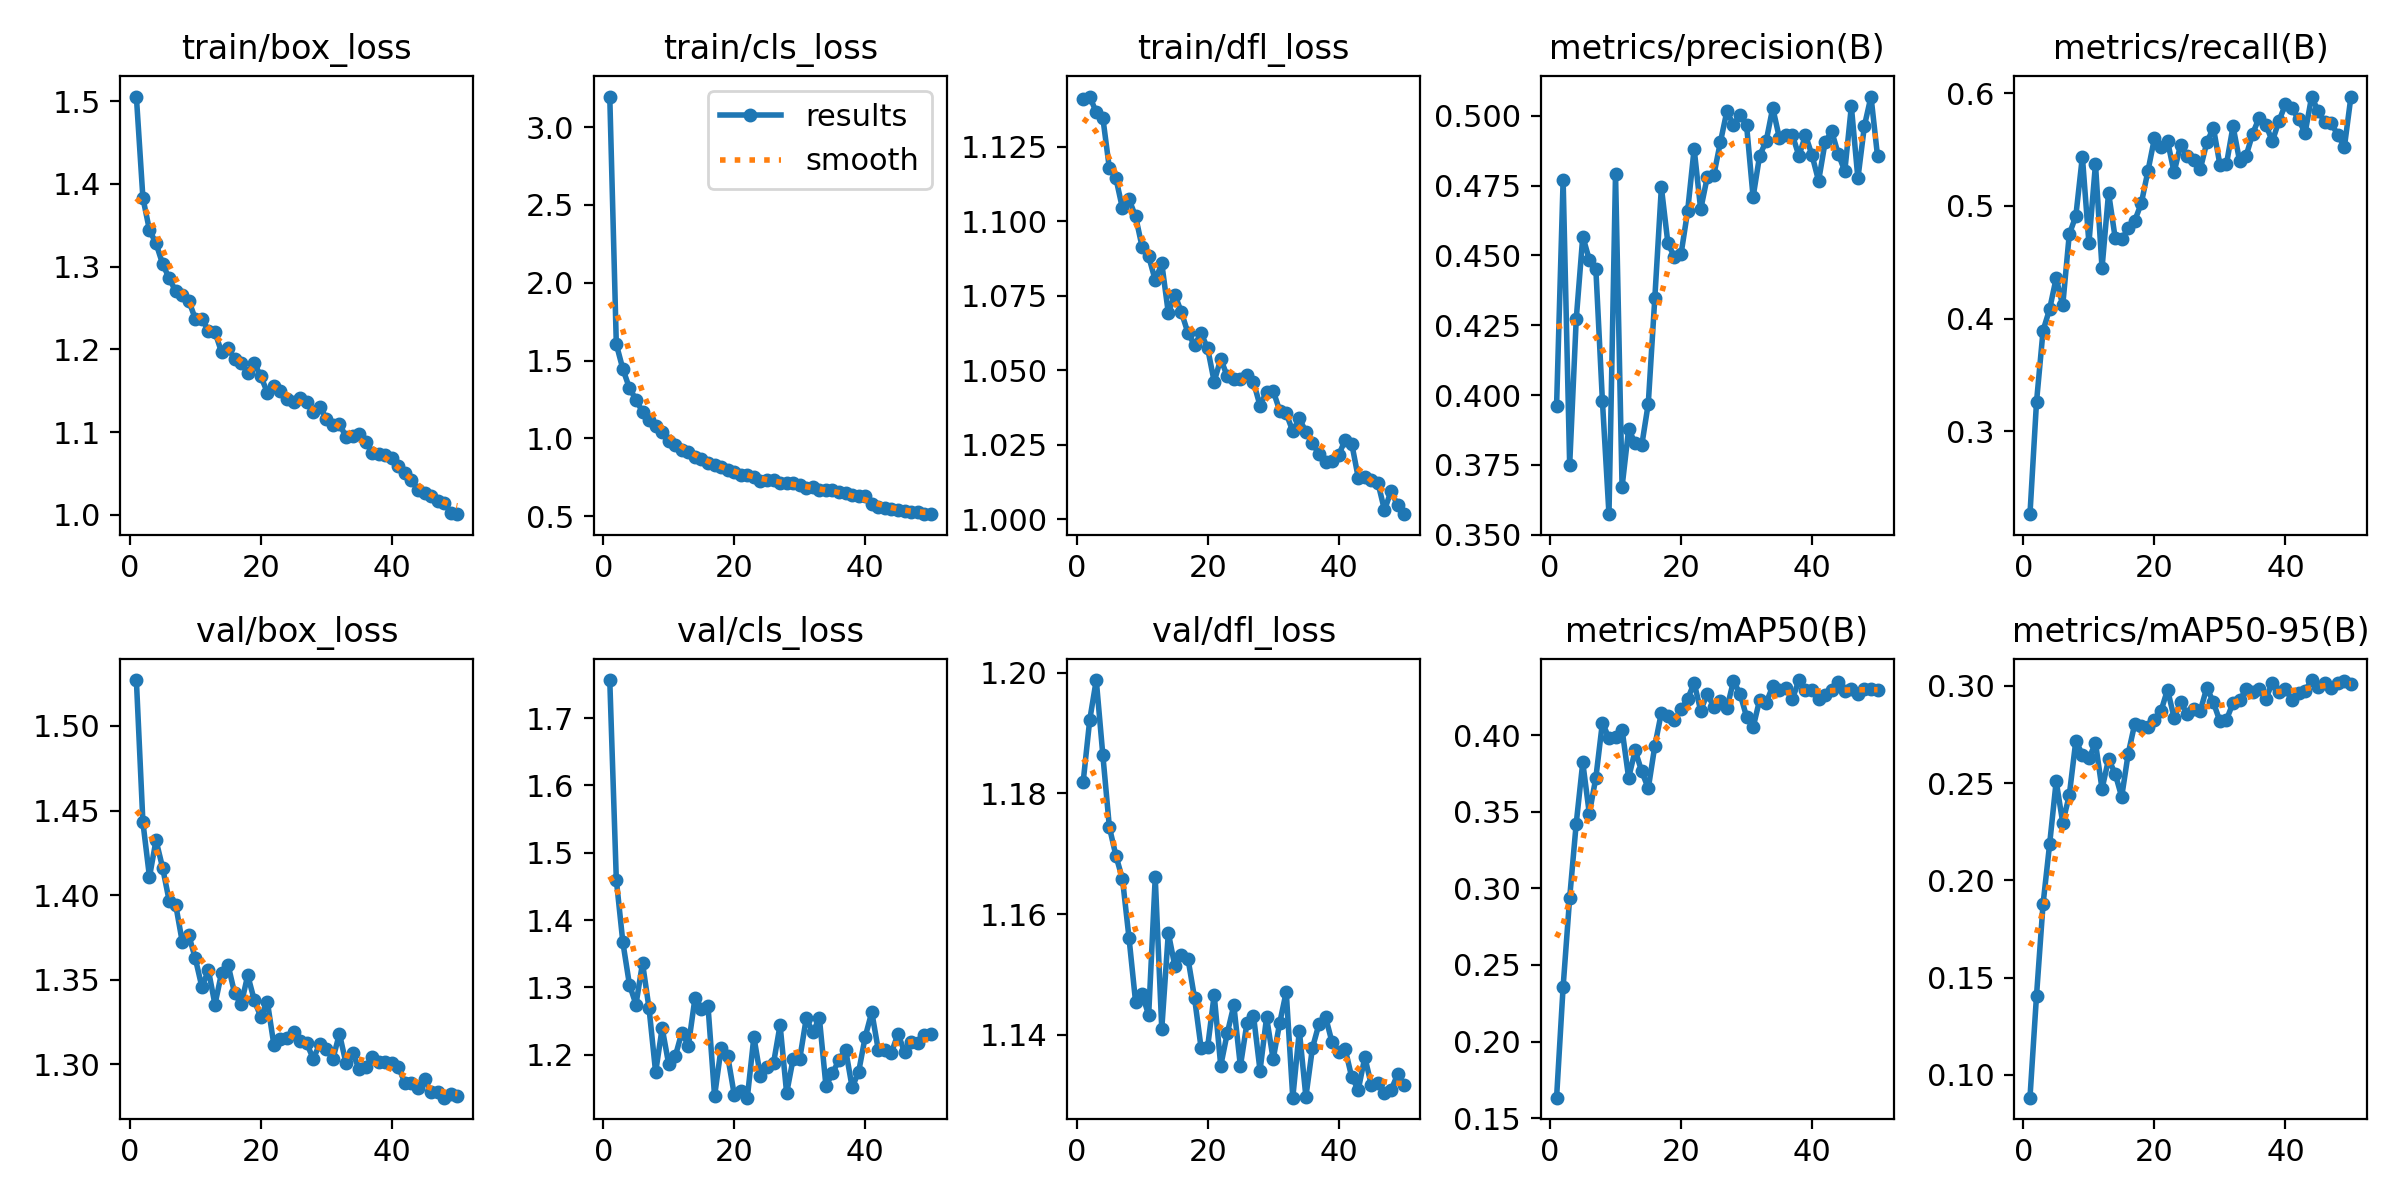

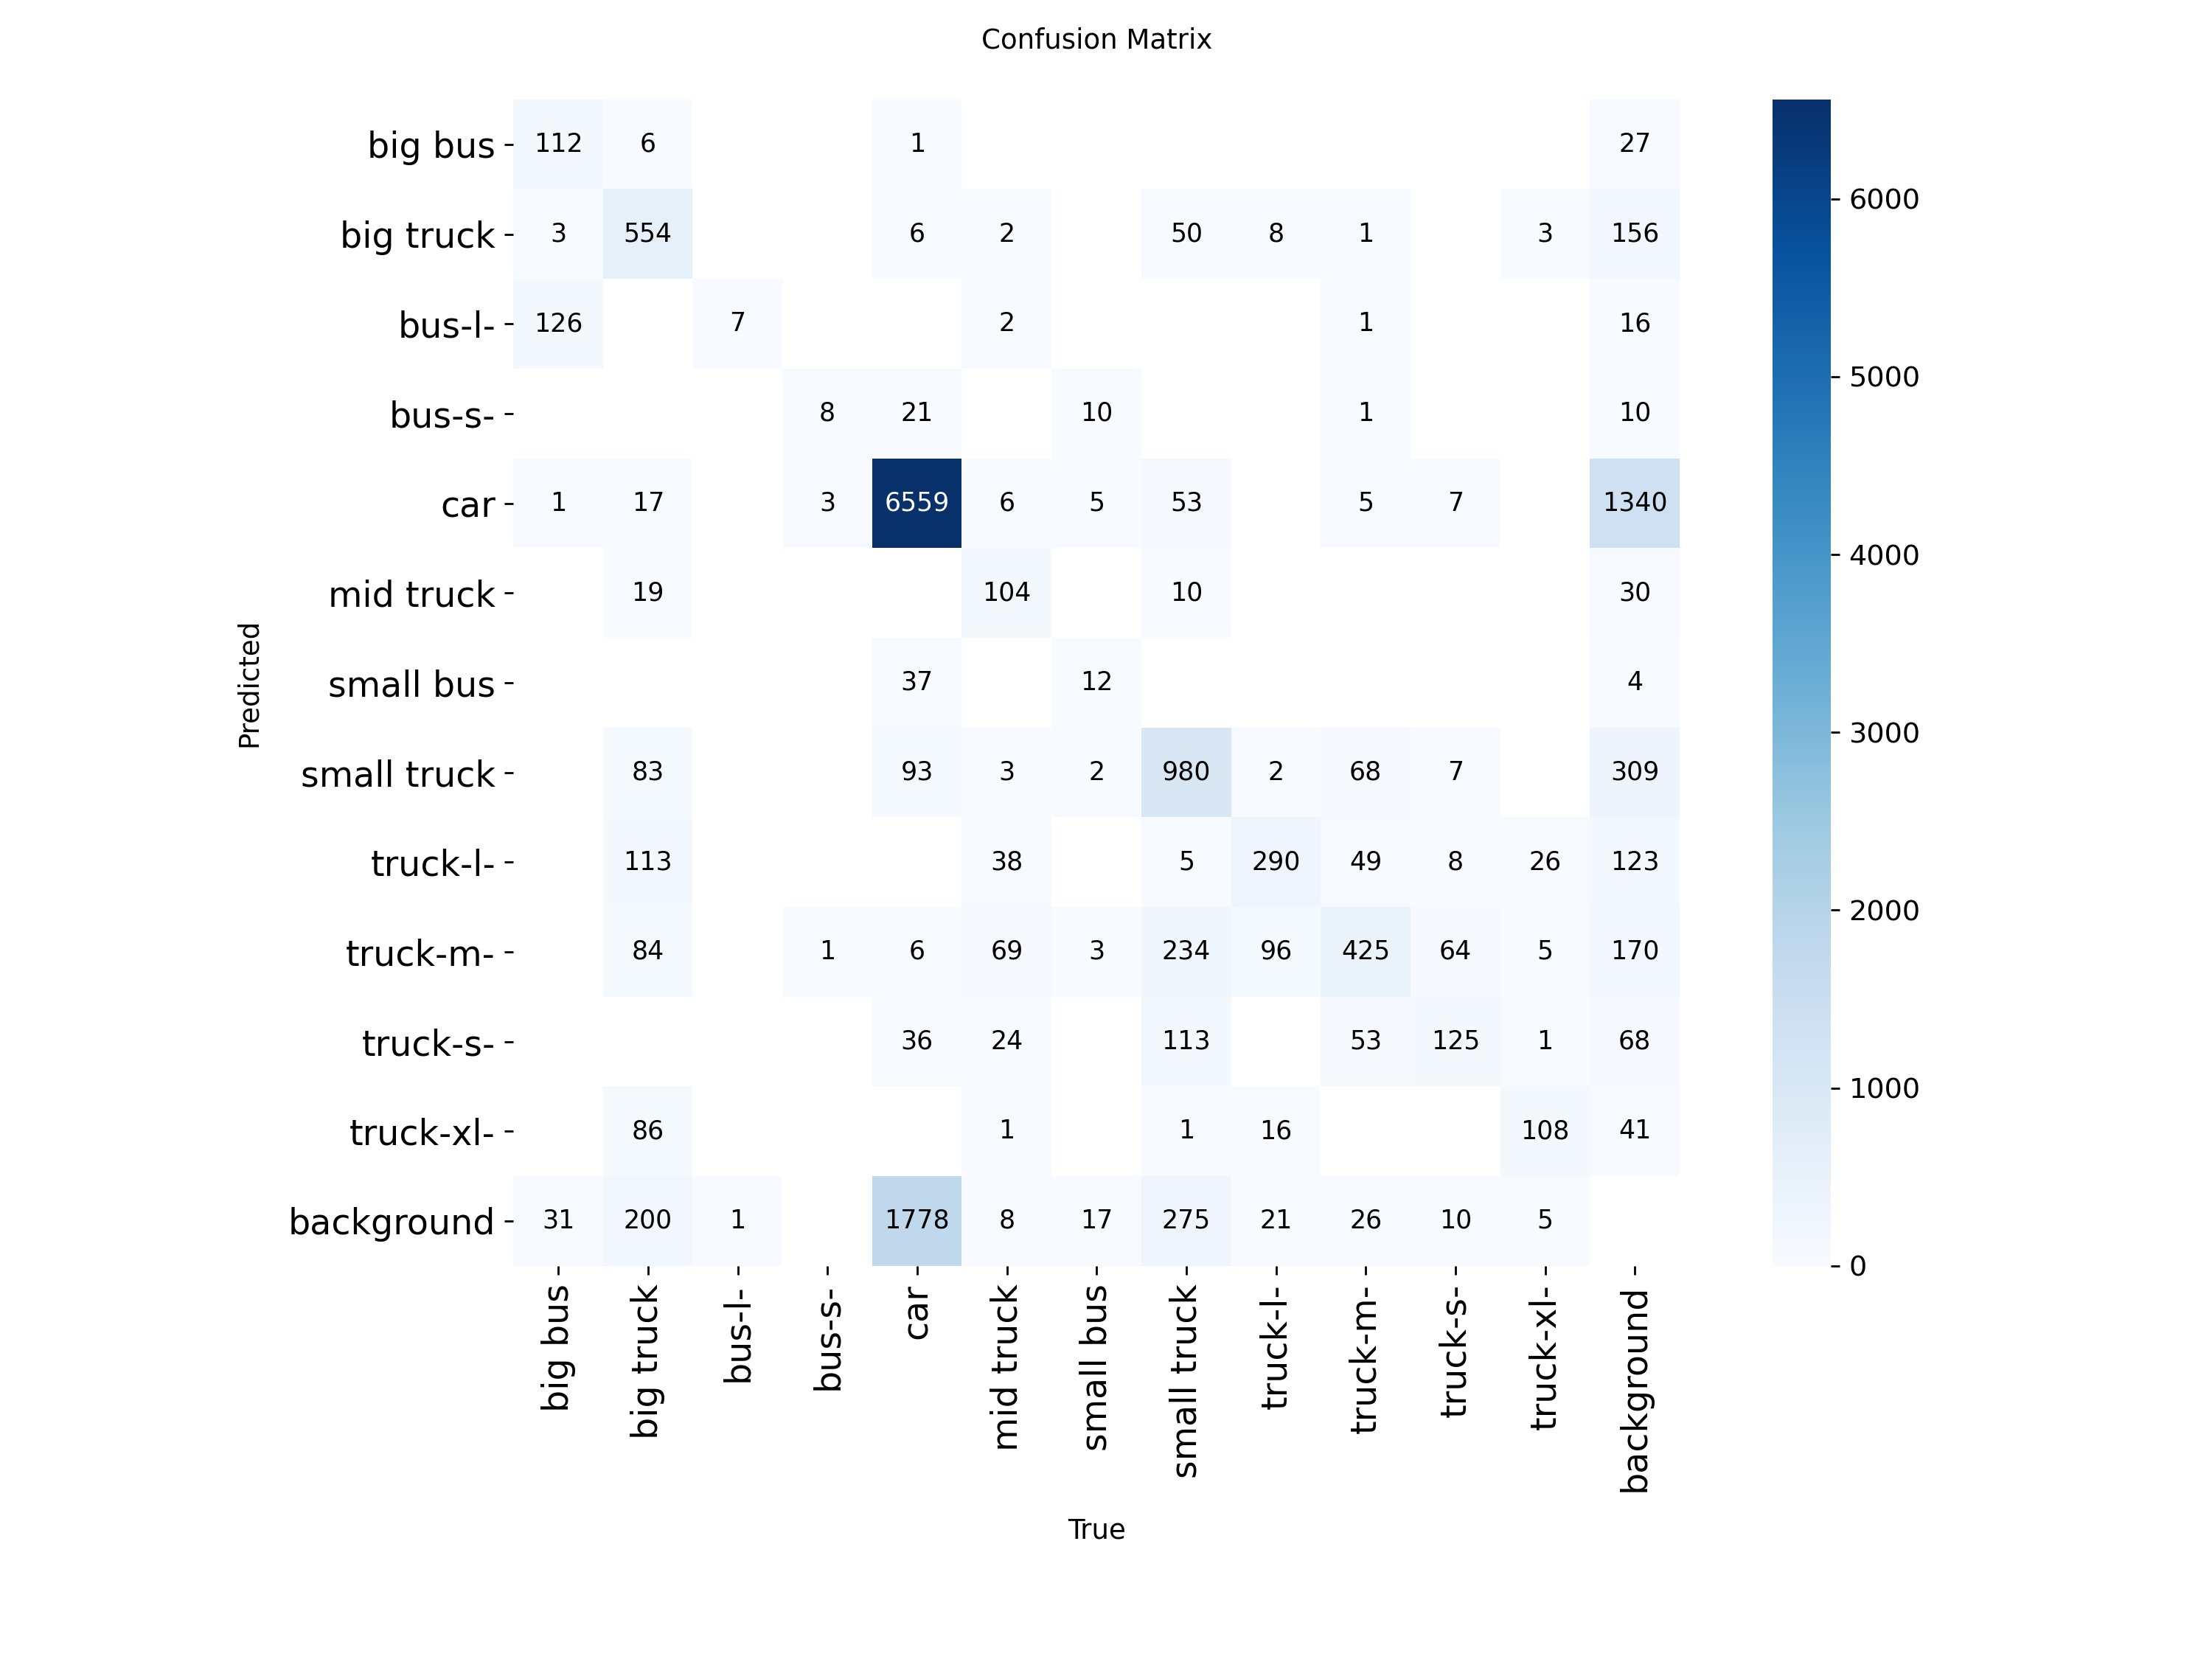

In [7]:
# Training curves and confusion matrix
from IPython.display import Image, display

RUN_DIR = Path(results.save_dir)
for name in ["results.png", "confusion_matrix.png"]:
    if (RUN_DIR / name).exists():
        display(Image(filename=str(RUN_DIR / name), width=900))

## 4. Evaluate the best model

In [8]:
best_model = YOLO(RUN_DIR / "weights" / "best.pt")

split = "test" if "test" in data_cfg else "val"
metrics = best_model.val(data=DATA_YAML, split=split, device=DEVICE, workers=0,
                         project=str(RUNS_DIR), name="val", exist_ok=True)

print(f"Split:     {split}")
print(f"mAP50:     {metrics.box.map50:.3f}")
print(f"mAP50-95:  {metrics.box.map:.3f}")
print(f"Precision: {metrics.box.mp:.3f}")
print(f"Recall:    {metrics.box.mr:.3f}")

Ultralytics 8.4.165  Python-3.12.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLOv12n summary (fused): 159 layers, 2,559,068 parameters, 0 gradients, 7.3 GFLOPs
WARNING val: Slow image access detected (ping: 0.00.0 ms, read: 9.82.7 MB/s, size: 58.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\dhafe\Desktop\Vehicle-detection\car-detection-1\test\labels... 458 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 458/458 499.7it/s 0.9s0.1s
val: New cache created: C:\Users\dhafe\Desktop\Vehicle-detection\car-detection-1\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 3.9it/s 7.4s0.2s
                   all        458       6222      0.467      0.531      0.391      0.263
               big bus         81        107       0.83      0.486      0.768      0.522
    

## 5. Run inference

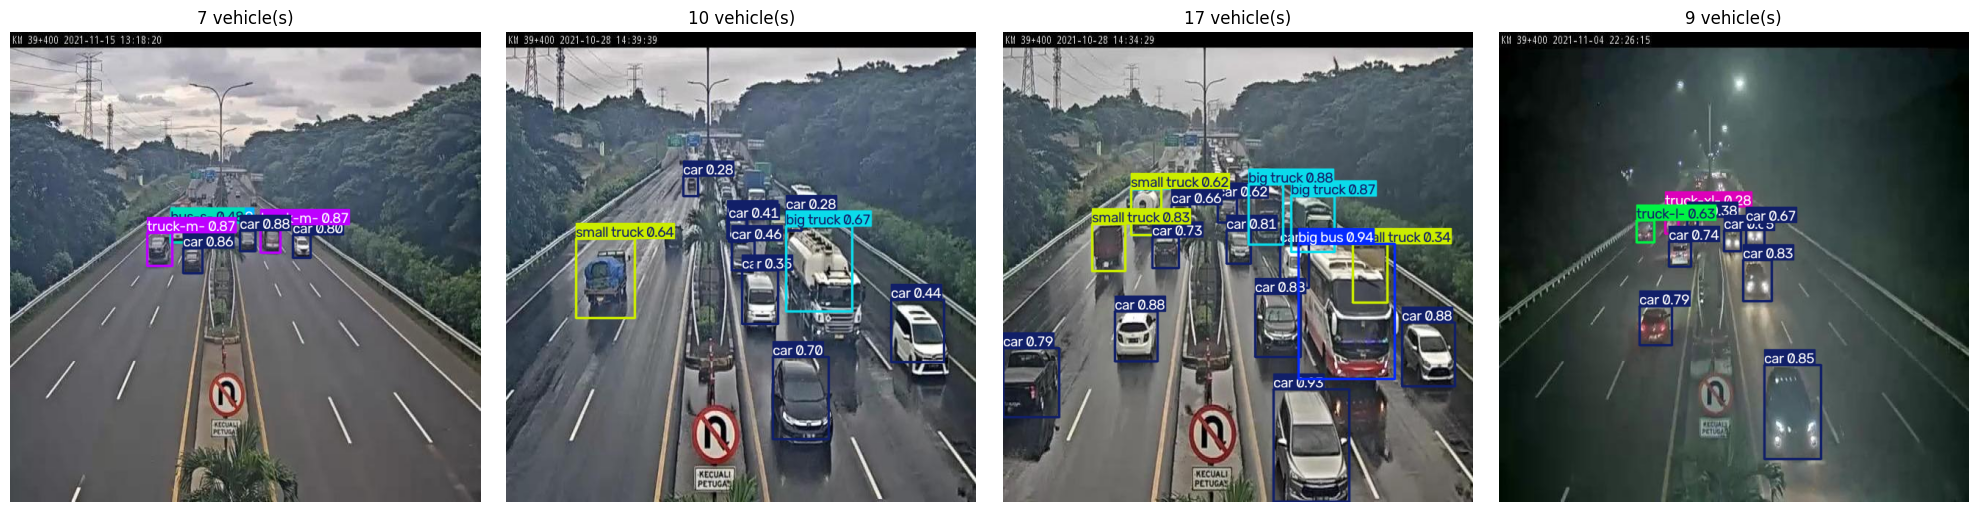

In [9]:
# Predict on a few test images
test_dir = DATASET_DIR / ("test" if split == "test" else "valid") / "images"
test_imgs = random.sample(list(test_dir.glob("*")), min(4, len(list(test_dir.glob("*")))))

preds = best_model.predict(test_imgs, conf=0.25, device=DEVICE, verbose=False)

fig, axes = plt.subplots(1, len(preds), figsize=(5 * len(preds), 5))
for ax, r in zip(axes if len(preds) > 1 else [axes], preds):
    ax.imshow(r.plot()[:, :, ::-1])  # BGR -> RGB
    ax.set_title(f"{len(r.boxes)} vehicle(s)")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
# Predict on your own image or video: set the path and run
SOURCE = "assets/cars.jpg"

if Path(SOURCE).exists():
    out = best_model.predict(SOURCE, conf=0.25, device=DEVICE, save=True,
                             project=str(RUNS_DIR), name="predict", exist_ok=True)
    print("Saved annotated output to:", out[0].save_dir)
else:
    print("Set SOURCE to an existing image or video file.")


image 1/1 C:\Users\dhafe\Desktop\Vehicle-detection\cars.jpg: 640x448 26 cars, 1 truck-l-, 83.5ms
Speed: 1.7ms preprocess, 83.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 448)
Results saved to C:\Users\dhafe\runs\detect\predict
Saved annotated output to: C:\Users\dhafe\runs\detect\predict


## 6. Run on a video (standalone: works right after a kernel restart)

Just run the next cell. It loads the trained model itself and writes `cars_video_detected.mp4` to the project folder, then opens it.

In [9]:
import os
import time
import cv2
import torch
from pathlib import Path
from ultralytics import YOLO

MODEL_PATH = Path("runs/vehicle_yolo12n/weights/best.pt")
VIDEO_IN = Path("assets/cars_in_traffic.mp4")
VIDEO_OUT = Path("assets/cars_video_detected.mp4")

model = YOLO(MODEL_PATH)
device = 0 if torch.cuda.is_available() else "cpu"

cap = cv2.VideoCapture(str(VIDEO_IN))
fps = cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

writer = cv2.VideoWriter(str(VIDEO_OUT), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
seen_ids = set()
t0 = time.time()
for r in model.track(str(VIDEO_IN), stream=True, conf=0.25, device=device, verbose=False):
    frame = r.plot(line_width=2)
    if r.boxes.id is not None:
        seen_ids.update(r.boxes.id.int().tolist())
    text = f"In frame: {len(r.boxes)}   Unique so far: {len(seen_ids)}"
    cv2.putText(frame, text, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 5)        # outline
    cv2.putText(frame, text, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
    writer.write(frame)
writer.release()

print(f"Done in {time.time() - t0:.0f}s, {len(seen_ids)} unique vehicles")
print("Saved to:", VIDEO_OUT.resolve())
os.startfile(VIDEO_OUT.resolve())  # opens in your default video player


Done in 51s, 149 unique vehicles
Saved to: C:\Users\dhafe\Desktop\Vehicle-detection\cars_video_detected.mp4


In [ ]:
# Optional: export to ONNX for deployment
# best_model.export(format="onnx")